In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV = "data/cmip6_zonal_warming_ensmean.csv"
SCENARIOS = ["ssp126", "ssp245", "ssp585"]
SCEN_LABEL = {
    "ssp126": "SSP1-2.6 (low)",
    "ssp245": "SSP2-4.5 (middle)",
    "ssp585": "SSP5-8.5 (high)",
}
SCEN_COLOR = {"ssp126": "#2b6cb0", "ssp245": "#dd8a1a", "ssp585": "#c0392b"}
LATE = (2081, 2100)
NOTE = "3-model CMIP6 mean (tas) · 5° latitude bands · warming vs 1995–2014"

# Regions as (lat_min, lat_max); each is a cos(latitude)-weighted mean of its 5° bands
REGIONS = {
    "Arctic (70–90°N)": (70, 90),
    "N. mid-latitudes (30–60°N)": (30, 60),
    "Tropics (20°S–20°N)": (-20, 20),
    "S. mid-latitudes (30–60°S)": (-60, -30),
    "Antarctic (60–90°S)": (-90, -60),
}
GLOBAL = (-90, 90)

ens = pd.read_csv(CSV)


def region_series(scen, lo, hi):
    """Year -> cos(lat)-weighted mean warming over bands between lo and hi."""
    d = ens[(ens.scenario == scen) & (ens.lat >= lo) & (ens.lat <= hi)].copy()
    d["w"] = np.cos(np.deg2rad(d.lat))
    d["ww"] = d.warming * d.w
    g = d.groupby("year")[["ww", "w"]].sum()
    return g.ww / g.w


def region_late(scen, lo, hi):
    return region_series(scen, lo, hi).loc[LATE[0] : LATE[1]].mean()


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)


def finish(fig, name):
    fig.text(0.01, 0.01, NOTE, fontsize=8, color="0.4")
    fig.tight_layout(rect=[0, 0.03, 1, 1])
    fig.savefig(name, dpi=150)
    plt.show()


ens.head()

,scenario,year,lat,warming
0,ssp126,2015,-87.5,0.766667
1,ssp126,2015,-82.5,1.016667
2,ssp126,2015,-77.5,0.917000
3,ssp126,2015,-72.5,0.601000
4,ssp126,2015,-67.5,0.185667


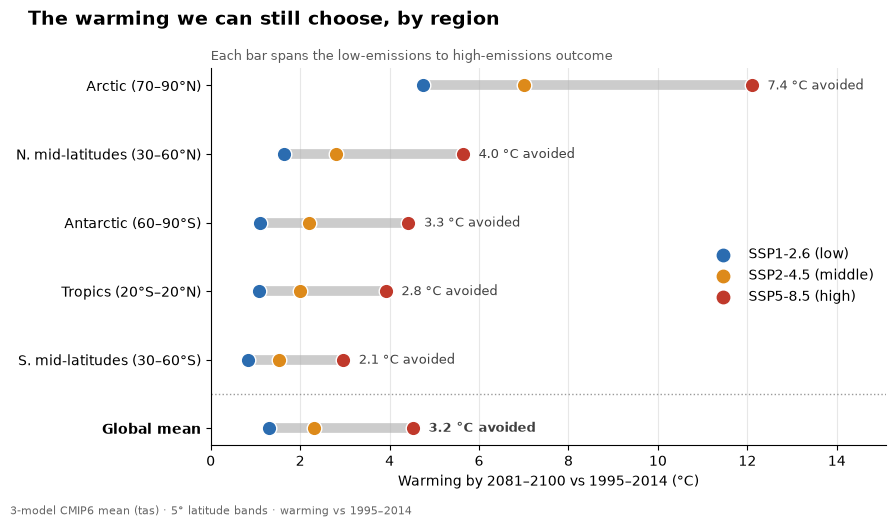

In [36]:
# Graph 4: dumbbell of warming under the low vs high scenario, by region
rows = []
for name, (lo, hi) in REGIONS.items():
    vals = {s: region_late(s, lo, hi) for s in SCENARIOS}
    rows.append((name, vals))
rows.sort(key=lambda r: r[1]["ssp585"] - r[1]["ssp126"])  # biggest gap ends up on top

gvals = {s: region_late(s, *GLOBAL) for s in SCENARIOS}

fig, ax = plt.subplots(figsize=(9, 5.2))
all_rows = [
    ("Global mean", gvals)
] + rows  # global drawn at the bottom as the reference
xmax = 0
for y, (name, vals) in enumerate(all_rows):
    lo_v, hi_v = vals["ssp126"], vals["ssp585"]
    ax.plot([lo_v, hi_v], [y, y], color="0.8", lw=7, solid_capstyle="round", zorder=1)
    for s in SCENARIOS:
        ax.scatter(
            vals[s], y, s=110, color=SCEN_COLOR[s], zorder=3, edgecolor="white", lw=1
        )
    ax.text(
        hi_v + 0.35,
        y,
        f"{hi_v - lo_v:.1f} °C avoided",
        va="center",
        fontsize=9,
        fontweight="bold" if name == "Global mean" else "normal",
        color="0.25",
    )
    xmax = max(xmax, hi_v)

ax.axhline(0.5, color="0.6", ls=":", lw=1)
ax.set_yticks(range(len(all_rows)))
ax.set_yticklabels([r[0] for r in all_rows])
ax.get_yticklabels()[0].set_fontweight("bold")
ax.set_xlim(0, xmax + 3)
ax.set_xlabel(f"Warming by {LATE[0]}–{LATE[1]} vs 1995–2014 (°C)")
for s in SCENARIOS:
    ax.scatter([], [], s=80, color=SCEN_COLOR[s], label=SCEN_LABEL[s])
ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.45), frameon=False)
fig.suptitle(
    "The warming we can still choose, by region",
    x=0.03,
    ha="left",
    fontsize=14,
    fontweight="bold",
)
ax.set_title(
    "Each bar spans the low-emissions to high-emissions outcome",
    loc="left",
    fontsize=9.5,
    color="0.35",
)
ax.grid(axis="x", alpha=0.3)
style(ax)
finish(fig, "g4_avoided_by_region.png")

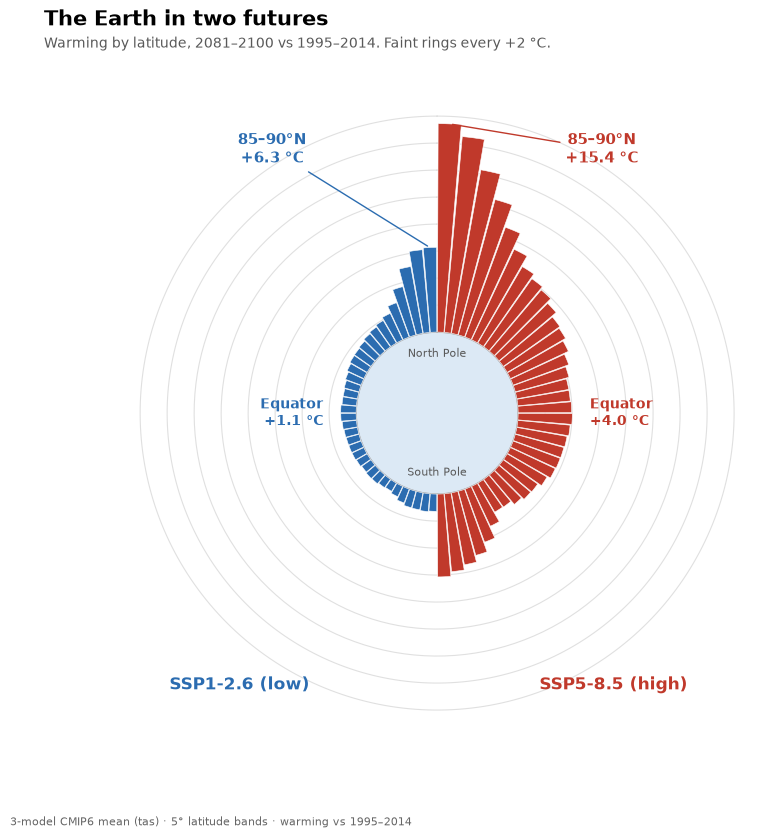

In [37]:
# Graph 5: "warming globe" - pole-to-pole warming wrapped around the Earth
# Left half = low-emissions scenario, right half = high-emissions scenario
LEFT, RIGHT = "ssp126", "ssp585"
R0 = 6.0  # radius of the Earth disc, in the same units as warming (°C)

late = (
    ens[ens.year.between(*LATE)]
    .groupby(["scenario", "lat"], as_index=False)
    .warming.mean()
)
wmax = late[late.scenario.isin([LEFT, RIGHT])].warming.max()
rmax = R0 + wmax + 2.8

fig = plt.figure(figsize=(8.5, 8.5))
ax = fig.add_subplot(111, projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)  # clockwise, so the right half is the east side
ax.set_ylim(0, rmax)
ax.set_axis_off()

ring = np.linspace(0, 2 * np.pi, 300)
for v in range(2, int(wmax) + 2, 2):  # faint rings every +2 °C
    ax.plot(ring, np.full_like(ring, R0 + v), color="0.88", lw=0.8, zorder=0)
ax.fill(ring, np.full_like(ring, R0), color="#dce9f5", zorder=1)
ax.plot(ring, np.full_like(ring, R0), color="0.6", lw=1, zorder=2)

for scen, side in [(RIGHT, 1), (LEFT, -1)]:
    d = late[late.scenario == scen].sort_values("lat")
    theta = side * np.deg2rad(
        90 - d.lat.values
    )  # north pole at the top, south pole at the bottom
    ax.bar(
        theta,
        d.warming.values,
        width=np.deg2rad(4.6),
        bottom=R0,
        color=SCEN_COLOR[scen],
        edgecolor="white",
        linewidth=0.4,
        zorder=3,
    )


def tip(scen, lat_target):
    d = late[late.scenario == scen]
    row = d.iloc[(d.lat - lat_target).abs().argmin()]
    return row.lat, row.warming


for scen, side in [(RIGHT, 1), (LEFT, -1)]:
    color = SCEN_COLOR[scen]
    lat, w = tip(scen, 87.5)  # Arctic tip
    ax.annotate(
        f"85–90°N\n+{w:.1f} °C",
        xy=(side * np.deg2rad(90 - lat), R0 + w),
        xytext=(side * np.deg2rad(32), rmax - 1.2),
        color=color,
        fontsize=11,
        fontweight="bold",
        ha="center",
        va="center",
        arrowprops=dict(arrowstyle="-", color=color, lw=1),
    )
    lat, w = tip(scen, 0)  # equator
    ax.text(
        side * np.deg2rad(90),
        R0 + w + 1.3,
        f"Equator\n+{w:.1f} °C",
        color=color,
        fontsize=10,
        fontweight="bold",
        va="center",
        ha="left" if side > 0 else "right",
    )

ax.text(
    0,
    R0 - 1.6,
    "North Pole",
    ha="center",
    va="center",
    fontsize=8,
    color="0.35",
    zorder=4,
)
ax.text(
    np.pi,
    R0 - 1.6,
    "South Pole",
    ha="center",
    va="center",
    fontsize=8,
    color="0.35",
    zorder=4,
)

fig.suptitle(
    "The Earth in two futures",
    x=0.05,
    y=0.97,
    ha="left",
    fontsize=15,
    fontweight="bold",
)
fig.text(
    0.05,
    0.925,
    f"Warming by latitude, {LATE[0]}–{LATE[1]} vs 1995–2014. Faint rings every +2 °C.",
    fontsize=10,
    color="0.35",
)
fig.text(
    0.28,
    0.17,
    SCEN_LABEL[LEFT],
    ha="center",
    fontsize=12,
    fontweight="bold",
    color=SCEN_COLOR[LEFT],
)
fig.text(
    0.72,
    0.17,
    SCEN_LABEL[RIGHT],
    ha="center",
    fontsize=12,
    fontweight="bold",
    color=SCEN_COLOR[RIGHT],
)
fig.text(0.01, 0.01, NOTE, fontsize=8, color="0.4")
fig.savefig("g5_warming_globe.png", dpi=150, bbox_inches="tight")
plt.show()

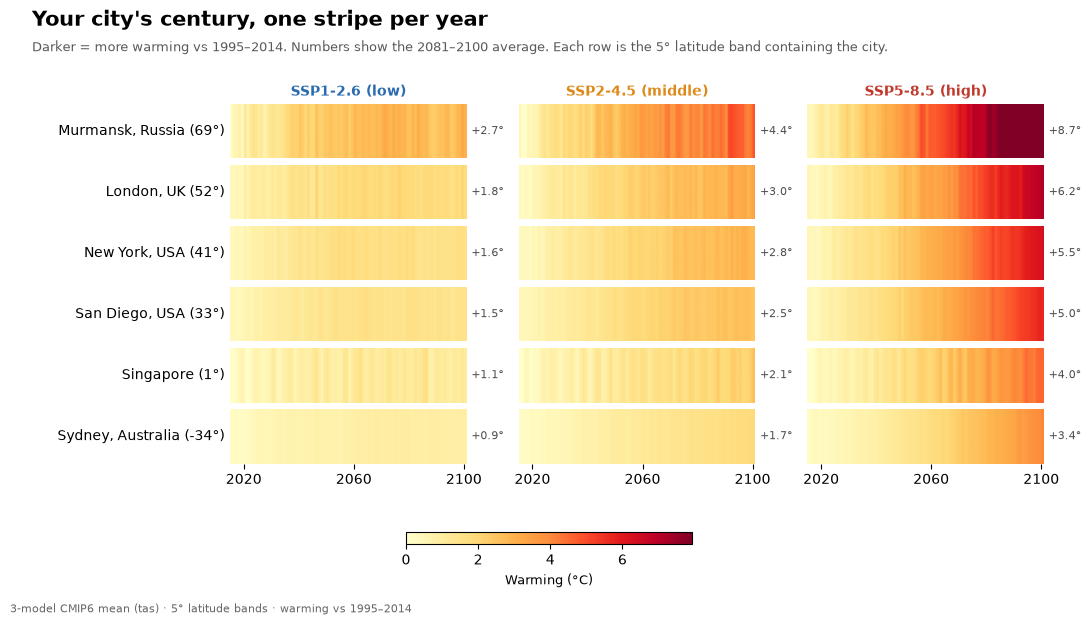

In [38]:
# Graph 6: climate stripes - one stripe per year (2015-2100), one row per city, one column per scenario
CITIES = {
    "Murmansk, Russia": 69.0,
    "London, UK": 51.5,
    "New York, USA": 40.7,
    "San Diego, USA": 32.7,
    "Singapore": 1.35,
    "Sydney, Australia": -33.9,
}
bands = np.sort(ens.lat.unique())


def band_of(lat):
    return bands[
        np.argmin(np.abs(bands - lat))
    ]  # 5-degree band containing the latitude


city_band = {c: band_of(lat) for c, lat in CITIES.items()}
vmax = np.percentile(
    ens[ens.lat.isin(city_band.values())].warming, 99
)  # shared color scale

fig, axes = plt.subplots(
    len(CITIES),
    3,
    figsize=(11, 6.2),
    sharex=True,
    gridspec_kw={"hspace": 0.12, "wspace": 0.22},
)
for i, (city, lat) in enumerate(CITIES.items()):
    for j, s in enumerate(SCENARIOS):
        ax = axes[i, j]
        d = ens[(ens.scenario == s) & (ens.lat == city_band[city])].sort_values("year")
        im = ax.imshow(
            d.warming.values[None, :],
            aspect="auto",
            cmap="YlOrRd",
            vmin=0,
            vmax=vmax,
            extent=[d.year.min(), d.year.max() + 1, 0, 1],
        )
        ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        end = d[d.year.between(*LATE)].warming.mean()
        ax.text(
            1.02,
            0.5,
            f"+{end:.1f}°",
            transform=ax.transAxes,
            va="center",
            fontsize=8,
            color="0.3",
        )
        if j == 0:
            ax.set_ylabel(
                f"{city} ({lat:.0f}°)", rotation=0, ha="right", va="center", fontsize=10
            )
        if i == 0:
            ax.set_title(
                SCEN_LABEL[s], fontsize=10, fontweight="bold", color=SCEN_COLOR[s]
            )
        if i < len(CITIES) - 1:
            ax.tick_params(bottom=False)
axes[-1, 0].set_xticks([2020, 2060, 2100])

fig.text(
    0.03,
    0.965,
    "Your city's century, one stripe per year",
    ha="left",
    va="center",
    fontsize=15,
    fontweight="bold",
)
fig.text(
    0.03,
    0.915,
    "Darker = more warming vs 1995–2014. Numbers show the 2081–2100 average. "
    "Each row is the 5° latitude band containing the city.",
    fontsize=9,
    color="0.35",
)
fig.subplots_adjust(left=0.21, right=0.95, top=0.83, bottom=0.25)
cax = fig.add_axes([0.37, 0.12, 0.26, 0.02])
fig.colorbar(im, cax=cax, orientation="horizontal").set_label(
    "Warming (°C)", fontsize=9
)
fig.text(0.01, 0.01, NOTE, fontsize=8, color="0.4")
fig.savefig("g6_city_stripes.png", dpi=150)
plt.show()